# Median Price per Square Metre

Training and evaluation on preprocessed property listings. EDA and dataset cleaning belong to `notebooks/`.

## 1. Setup

In [1]:
from pathlib import Path
import os
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "experiments").is_dir() and (path / "requirements.txt").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from experiments.data import load_data, default_data_path, SEED, NUMERIC, CATEGORICAL
from experiments.evaluation import (
    select_candidate, inverse_log, record_result, diagnostics,
    importance_plot, comparison_table,
)
from experiments.estimators import (
    structured_preprocessor, native_features, catboost_features,
    text_pipeline, text_inputs, MedianPricePerSqm,
)

np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
DATA_PATH = default_data_path()  # Replace with another preprocessed Parquet path if needed.

## 2. Load Preprocessed Data

The default input is `data/processed/priced_listings.parquet`, exported by the EDA notebook. If it is absent, the existing `experiment_cohort.parquet` is used and its path is displayed below. Set `DATA_PATH` to select a file explicitly. Existing split labels are reused; otherwise a shared 70/15/15 split is created. Every input row is retained. No source download, EDA, cleaning, sampling, or deduplication runs here.

In [2]:
parts, manifest = load_data(DATA_PATH)
train, validation, test = (parts[name] for name in ["train", "validation", "test"])
y_train = train.price.to_numpy()
y_validation = validation.price.to_numpy()
log_y_train = np.log1p(y_train)
log_y_validation = np.log1p(y_validation)
display(pd.Series({"Input": manifest["input_path"], "Seed": SEED,
                   "Split": manifest["split_method"],
                   **manifest["split_counts"]}, name="Training settings").to_frame())

,Training settings
Input,data/processed/experiment_cohort.parquet
Seed,42
Split,existing split column (unchanged)
train,41663
validation,8928
test,8928


## 3. Model

Training unit price is `price / area`. The primary key is `(province-qualified district, property_type_name)`; adding province disambiguates districts with identical names. Unseen keys fall back to `(province, property type)`, then property type, then the global training median unit price. Missing keys are explicit categories. At inference, invalid areas fall back to the median positive training area; all evaluated cohort areas are positive and finite. Sparse groups have no minimum-count threshold and may be unstable. No evaluation prices contribute to any median.

Only training observations fit imputation, encoding, scaling, or TF-IDF. Nonbaseline estimators learn log1p prices and reverse the transformation for evaluation; predictions are bounded by the training price range. Target-derived columns are excluded from the predictors.

In [3]:
def fit_candidate(parameters):
    return MedianPricePerSqm().fit(train, y_train)

def predict_frame(estimator, frame):
    return estimator.predict(frame)

## 4. Hyperparameters

Select the candidate with the lowest validation MAE in VND. Test targets are not used for selection.

In [4]:
candidates = [{}]
display(pd.DataFrame(candidates))

""
0


## 5. Train

In [5]:
model, selected_parameters, tuning_results = select_candidate(
    candidates, fit_candidate, y_validation,
    lambda estimator: predict_frame(estimator, validation))
display(tuning_results)
display(pd.Series(selected_parameters, dtype=object, name="Selected value").to_frame())

,MAE,RMSE,R2,MAPE,fit_seconds
0,1.320936e+10,6.493642e+11,-277.896952,760002.103488,0.113124


,Selected value


## 6. Evaluate and Save Results

MAE and RMSE use original VND prices; R-squared is unitless and MAPE is a percentage. Metrics include every evaluation row. The residual histogram displays the central 98% range without changing scoring. Results and row-aligned predictions are saved under `reports/experiments/`.

,Test listings
district_type,8870
province_type,53
type,5


,MAE,RMSE,R2,MAPE
Split,,,,
validation,"13,209,360,798","649,364,204,353",-277.8970,"760,002.10"
test,"39,768,818,191","2,968,655,086,029",-0.0016,44.85


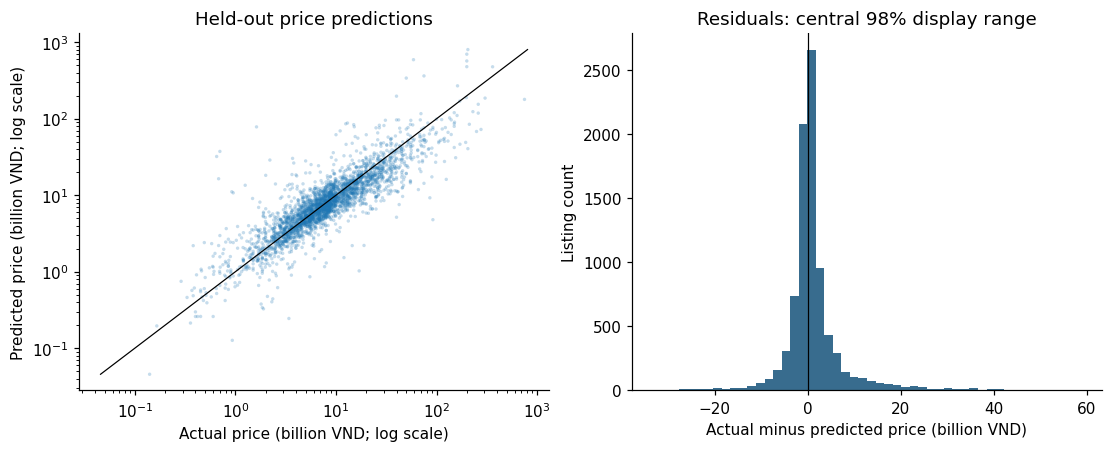

In [6]:
validation_prediction = predict_frame(model, validation)
test_prediction = predict_frame(model, test)
extra = {}
_, fallback_levels = model.predict_with_fallback(test)
display(pd.Series(fallback_levels).value_counts().rename("Test listings").to_frame())
extra["test_fallback_counts"] = {str(k): int(v) for k, v in pd.Series(fallback_levels).value_counts().items()}
result, evaluation_table = record_result(
    "median", manifest, parts, validation_prediction, test_prediction,
    selected_parameters, tuning_results, extra=extra)
display(evaluation_table.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                      "R2": "{:.4f}", "MAPE": "{:,.2f}"}))
diagnostics("median", test.price, test_prediction)

In [7]:
comparison = comparison_table(manifest)
display(comparison.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                 "R2": "{:.4f}", "MAPE": "{:,.2f}"}))

,Model,MAE,RMSE,R2,MAPE
0,Dummy Regressor,"45,548,775,416","2,966,493,482,061",-0.0001,259.20
1,Median Price per sqm,"39,768,818,191","2,968,655,086,029",-0.0016,44.85
